1.   **Classification on Vehicle Inspection Data**
2.   **Anna Korostelyova**
3.   **Context**:
    Vehicle Inspection dataset contains information on charachteristics of vehicles and whether these vehicles have passed inspection. During this assignment I practiced EDA, Supervised Lerning (Logistic regression and Tree-based methods), and reported my findings. Main task was to build the model which is going to predict whether a vehicle would pass vehicle inspection.
4.   **Findings**
 *   As the task about building the model, I'll explain what was interesting to encounter during the modelling
 *   If the data on KDE plot is too skewed, we can apply logistic transformation to see the pattern
 *   There might be leackge of data in case we include some variables which directly influence the result of inspection (e.g. inspection_conclusion_en). It would result in roc_auc score being equal to 1. Although I didn't directly showed it in my notebook, when I was experimenting, I encoutered that roc_auc score for both models was equal to 1.
 *   Dataset is wired so, that we should care more about false positives and percision score, because most essential thing is not to let people to drive junk cars.
 *   Even though my model is not predicting well enough, I've learned how to do the modelling and how to wait for 4 hours for only one cell of code to be executed. And I did my best.

## EDA

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
df = pd.read_parquet("inspection.parquet")

In [ ]:
df = df[(df['class'] == 'M1') & (df['inspection_type_en'] == 'Technical inspection')]

I'm not gonna adjust dataset for class imbalance right now => I'll sample 1000000 randomly

In [ ]:
df = df.sample(n=1000000, random_state=42)

In [ ]:
df

,unique_identifier,vehicle_identifier,registration_number,registration_number_markings,vin_number,make,model,class,body_type,special_purpose,...,mileage_km,inspection_station_code,inspection_station_municipality,inspection_type,inspection_type_en,inspection_conclusion_en,inspection_conclusion,inspection_passed,inspection_date_week,inspection_periodicity_months
4015085,57cc8713506f0f7,e5cc35a59c6aad5,428cebae95e05c3,None,3b78242c7bd8c85,VW,PASSAT,M1,AA,None,...,241652.0,de75f7819160c4d,Širvintų r. sav.,Techninė apžiūra,Technical inspection,Major deficiencies,Dideli trukūmai,False,2016-05-06,24.0
1975954,2b409b1e4fca29b,3fd47d88437c88c,0273562429d027c,None,267c451b0edaeb8,AUDI,AUDI A6,M1,AC,None,...,218841.0,1a3111edea0d1ff,Jonavos r. sav.,Techninė apžiūra,Technical inspection,No deficiencies,Be trūkumų,True,2020-11-18,24.0
11395455,f90d22897995603,f093d1c8c792f05,cb9435a45a9cb52,None,a12e5adee728e08,AUDI,A6,M1,AA,None,...,221452.0,d2a13f261b36655,Akmenės r. sav.,Techninė apžiūra,Technical inspection,No deficiencies,Be trūkumų,True,2018-06-25,24.0
11475991,fad2b8138300bab,78fe5fe18c1a110,0c13e306f7b5a3e,None,7012673711c53a3,TOYOTA,AYGO,M1,AB,None,...,100997.0,27beada5a5881cb,Kauno m. sav.,Techninė apžiūra,Technical inspection,No deficiencies,Be trūkumų,True,2018-01-08,24.0
5774541,7e512ac03eddf96,314f6e6a262d630,b9911bb4db43aff,None,ec2cc3b6d376c4e,AUDI,A6 AVANT,M1,None,None,...,367693.0,5feaf2b4e8cd248,Vilniaus m. sav.,Techninė apžiūra,Technical inspection,No deficiencies,Be trūkumų,True,2020-10-14,24.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8519797,ba503302137216c,d08b52ac316d965,d9650c5583fa279,None,e744f98e64b8bcd,MAZDA,6,M1,AC,None,...,238079.0,cad58212a375e95,Alytaus m. sav.,Techninė apžiūra,Technical inspection,No deficiencies,Be trūkumų,True,2015-10-01,24.0
11276306,f6719bafe3dca90,f730c007a82c310,1e3ef1389ca443a,None,8f915b414b2dadf,SUZUKI,BALENO,M1,AC,None,...,173880.0,7c1744d54b7370b,Alytaus r. sav.,Techninė apžiūra,Technical inspection,Minor deficiencies,Nedideli trukūmai,True,2020-08-26,24.0
6387618,8bb5fa2c32da1c3,a65e4664a896eb8,1336531831698c3,None,f309ab2853e3058,BMW,X3 3.0D,M1,AC,None,...,239207.0,5b6ba1a99dcd817,Prienų r. sav.,Techninė apžiūra,Technical inspection,Major deficiencies,Dideli trukūmai,False,2018-07-23,24.0
1588913,22c483c8f54b560,7975706cc9e3b62,e9dac8f038337a3,None,3f86e6d4234a13e,AUDI,A5,M1,None,None,...,286076.0,7976fd1123e9c83,Vilniaus m. sav.,Techninė apžiūra,Technical inspection,Minor deficiencies,Nedideli trukūmai,True,2024-04-01,24.0


Feature engenering

In [ ]:
df['inspection_date_week'] = pd.to_datetime(df['inspection_date_week'], format='%Y-%W-%w')
df['vehicle_age'] = df['inspection_date_week'].dt.year - df['manufacture_year']
df['end_of_year_inspection'] = (df['inspection_date_week'].dt.month >= 11).astype(int)

In [ ]:
df.isnull().sum()/len(df)

unique_identifier                  0.000000
vehicle_identifier                 0.000000
registration_number                0.000000
registration_number_markings       1.000000
vin_number                         0.000000
make                               0.000004
model                              0.006129
class                              0.000000
body_type                          0.257882
special_purpose                    0.995104
manufacture_year                   0.003794
fuel_type                          0.000147
smoke_emission                     0.366105
co_emission_standard               0.705501
co_emission_elevated               0.829280
mileage_km                         0.000002
inspection_station_code            0.000000
inspection_station_municipality    0.000000
inspection_type                    0.000000
inspection_type_en                 0.000000
inspection_conclusion_en           0.000000
inspection_conclusion              0.000000
inspection_passed               

In [ ]:
print(df.nunique())

unique_identifier                  1000000
vehicle_identifier                  824546
registration_number                 807106
registration_number_markings             0
vin_number                          824479
make                                   660
model                                11440
class                                    1
body_type                               13
special_purpose                         10
manufacture_year                        89
fuel_type                                9
smoke_emission                        1042
co_emission_standard                   143
co_emission_elevated                   128
mileage_km                          364731
inspection_station_code                 65
inspection_station_municipality         52
inspection_type                          1
inspection_type_en                       1
inspection_conclusion_en                 4
inspection_conclusion                    4
inspection_passed                        2
inspection_

In [ ]:
df.describe()

,manufacture_year,smoke_emission,co_emission_standard,co_emission_elevated,mileage_km,inspection_date_week,inspection_periodicity_months,vehicle_age,end_of_year_inspection
count,996206.000000,633895.000000,294499.000000,170720.000000,9.999980e+05,1000000,1000000.000000,996206.000000,1000000.000000
mean,2004.872347,0.987674,0.347663,0.117805,2.445251e+05,2020-02-14 04:03:55.814400256,23.824746,14.737652,0.146203
min,1012.000000,0.000000,0.000000,0.000000,0.000000e+00,2015-01-08 00:00:00,6.000000,-4.000000,0.000000
25%,2001.000000,0.120000,0.000000,0.000000,1.751720e+05,2017-08-27 00:00:00,24.000000,11.000000,0.000000
50%,2005.000000,0.520000,0.100000,0.000000,2.390900e+05,2020-03-04 00:00:00,24.000000,15.000000,0.000000
75%,2009.000000,1.300000,0.300000,0.100000,2.970530e+05,2022-08-13 00:00:00,24.000000,18.000000,0.000000
max,2024.000000,9999.000000,100.000000,60.000000,2.036420e+09,2025-01-08 00:00:00,60.000000,1012.000000,1.000000
std,6.730895,12.643898,1.028152,0.526038,2.759613e+06,NaN,1.960338,6.209899,0.353310


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1000000 entries, 4015085 to 3343915
Data columns (total 27 columns):
 #   Column                           Non-Null Count    Dtype         
---  ------                           --------------    -----         
 0   unique_identifier                1000000 non-null  object        
 1   vehicle_identifier               1000000 non-null  object        
 2   registration_number              1000000 non-null  object        
 3   registration_number_markings     0 non-null        object        
 4   vin_number                       1000000 non-null  object        
 5   make                             999996 non-null   object        
 6   model                            993871 non-null   object        
 7   class                            1000000 non-null  object        
 8   body_type                        742118 non-null   object        
 9   special_purpose                  4896 non-null     object        
 10  manufacture_year             

I'm gonna drop:
* 'unique_identifier', 'vehicle_identifier', 'registration_number', 'vin_number', and 'inspection_station_code' - it's just individual codes, i don't think that they going to influence prediction
* 'inspection_type', 'inspection_conclusion' - columns in lithuanian which ar edeblicated in english
* 'inspection_date_week' and 'manufacturing_date' were used for feature engeneering
*  'inspection_type_en' and 'class' were used for filtering => we don't need them anymore
* 'registration_number_markings', 'co_emission_standard', 'co_emission_elevated', 'special_purpose' - 2/3 are missing => better to delete them

In [ ]:
df = df.drop(columns=['unique_identifier', 'vehicle_identifier', 'registration_number', 'registration_number_markings', 'vin_number', 'inspection_station_code', 'inspection_type', 'inspection_type_en', 'inspection_conclusion', 'class', 'co_emission_standard', 'co_emission_elevated', 'special_purpose', 'inspection_date_week', 'manufacture_year'])

In [ ]:
df

,make,model,body_type,fuel_type,smoke_emission,mileage_km,inspection_station_municipality,inspection_conclusion_en,inspection_passed,inspection_periodicity_months,vehicle_age,end_of_year_inspection
4015085,VW,PASSAT,AA,"benzinas,dujos",NaN,241652.0,Širvintų r. sav.,Major deficiencies,False,24.0,19.0,0
1975954,AUDI,AUDI A6,AC,dyzelinas,0.05,218841.0,Jonavos r. sav.,No deficiencies,True,24.0,13.0,1
11395455,AUDI,A6,AA,dyzelinas,0.03,221452.0,Akmenės r. sav.,No deficiencies,True,24.0,7.0,0
11475991,TOYOTA,AYGO,AB,benzinas,NaN,100997.0,Kauno m. sav.,No deficiencies,True,24.0,10.0,0
5774541,AUDI,A6 AVANT,None,dyzelinas,0.20,367693.0,Vilniaus m. sav.,No deficiencies,True,24.0,12.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
8519797,MAZDA,6,AC,dyzelinas,2.58,238079.0,Alytaus m. sav.,No deficiencies,True,24.0,9.0,0
11276306,SUZUKI,BALENO,AC,benzinas,NaN,173880.0,Alytaus r. sav.,Minor deficiencies,True,24.0,19.0,0
6387618,BMW,X3 3.0D,AC,dyzelinas,0.49,239207.0,Prienų r. sav.,Major deficiencies,False,24.0,13.0,0
1588913,AUDI,A5,None,dyzelinas,1.04,286076.0,Vilniaus m. sav.,Minor deficiencies,True,24.0,17.0,0


Dealing with 'CENZŪRUOTA'

In [ ]:
columns_to_check = df.columns[:]

for col in columns_to_check:
    df = df[df[col].astype(str).str.contains('CENZŪRUOTA', case=False, na=False) == False]

Now there is no 'cenzūruota' present in the dataset

In [ ]:
df['inspection_passed'] = df['inspection_passed'].astype(int)
df['end_of_year_inspection'] = df['end_of_year_inspection'].astype(int)

In [ ]:
print(df.nunique())

make                                  659
model                               11439
body_type                              13
fuel_type                               9
smoke_emission                       1042
mileage_km                         357572
inspection_station_municipality        52
inspection_conclusion_en                4
inspection_passed                       2
inspection_periodicity_months           5
vehicle_age                            94
end_of_year_inspection                  2
dtype: int64


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 949104 entries, 4015085 to 1588913
Data columns (total 12 columns):
 #   Column                           Non-Null Count   Dtype  
---  ------                           --------------   -----  
 0   make                             949100 non-null  object 
 1   model                            942975 non-null  object 
 2   body_type                        716516 non-null  object 
 3   fuel_type                        948988 non-null  object 
 4   smoke_emission                   606308 non-null  float64
 5   mileage_km                       949102 non-null  float64
 6   inspection_station_municipality  949104 non-null  object 
 7   inspection_conclusion_en         949104 non-null  object 
 8   inspection_passed                949104 non-null  int32  
 9   inspection_periodicity_months    949104 non-null  float64
 10  vehicle_age                      946061 non-null  float64
 11  end_of_year_inspection           949104 non-null  int32  
dtype

Plotting

As make, model, inspection_station_municipality have too many values, for plotting I'll select only most frequent 10 values in order to plot them

In [ ]:
target = "inspection_passed"

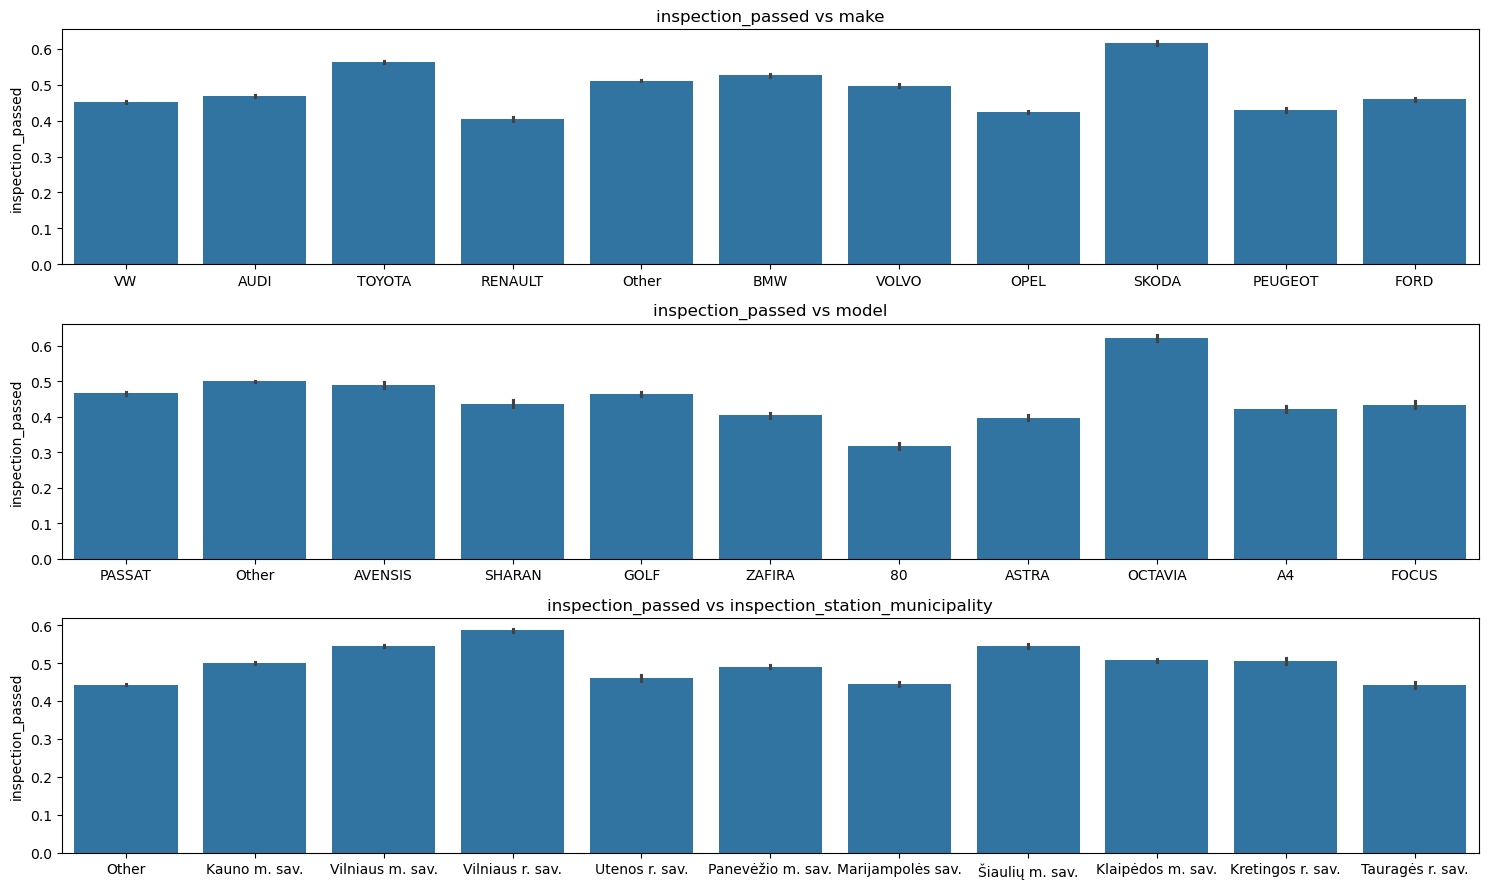

In [ ]:
df_too_many = pd.DataFrame(df[target])
columns_too_many = ['make', 'model', 'inspection_station_municipality']
fig, axs = plt.subplots(3, 1, figsize=(15, 3 * len(columns_too_many)))
axs = axs.flatten()

for i, predictor in enumerate(columns_too_many):
    top_makes = df[predictor].value_counts().nlargest(10).index
    df_too_many[predictor] = df[predictor].apply(lambda x: x if x in top_makes else 'Other')
    sns.barplot(x=predictor, y=target, data=df_too_many, ax=axs[i])
    axs[i].set_title(f'{target} vs {predictor}')
    axs[i].set_xlabel(None)
    axs[i].set_ylabel(target)

plt.tight_layout()
plt.show()

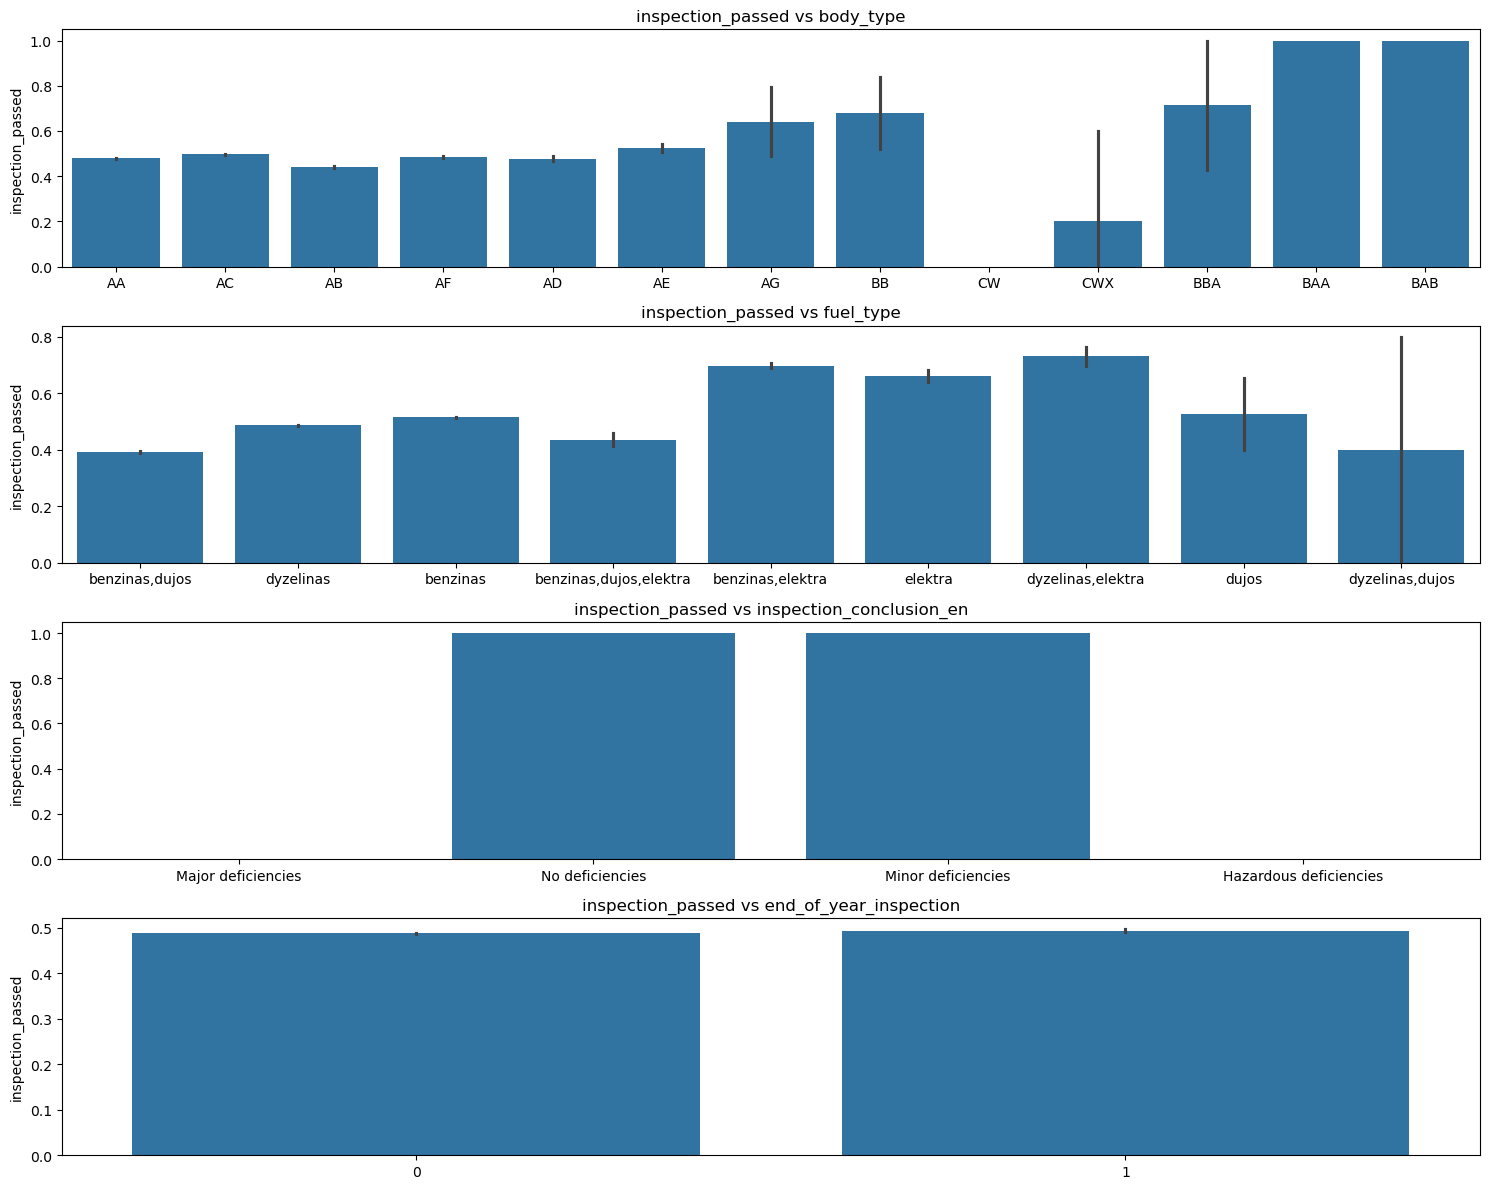

In [ ]:
cat_columns = ['body_type', 'fuel_type', 'inspection_conclusion_en', 'end_of_year_inspection']
fig, axs = plt.subplots(4, 1, figsize=(15, 3 * len(cat_columns)))
axs = axs.flatten()

for i, predictor in enumerate(cat_columns):
    sns.barplot(x=predictor, y=target, data=df, ax=axs[i])
    axs[i].set_title(f'{target} vs {predictor}')
    axs[i].set_xlabel(None)
    axs[i].set_ylabel(target)

plt.tight_layout()
plt.show()

For numerical predictors data is extremely skewed => I will use logistic transformation

C:\Users\User\anaconda3\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)
C:\Users\User\anaconda3\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: invalid value encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)


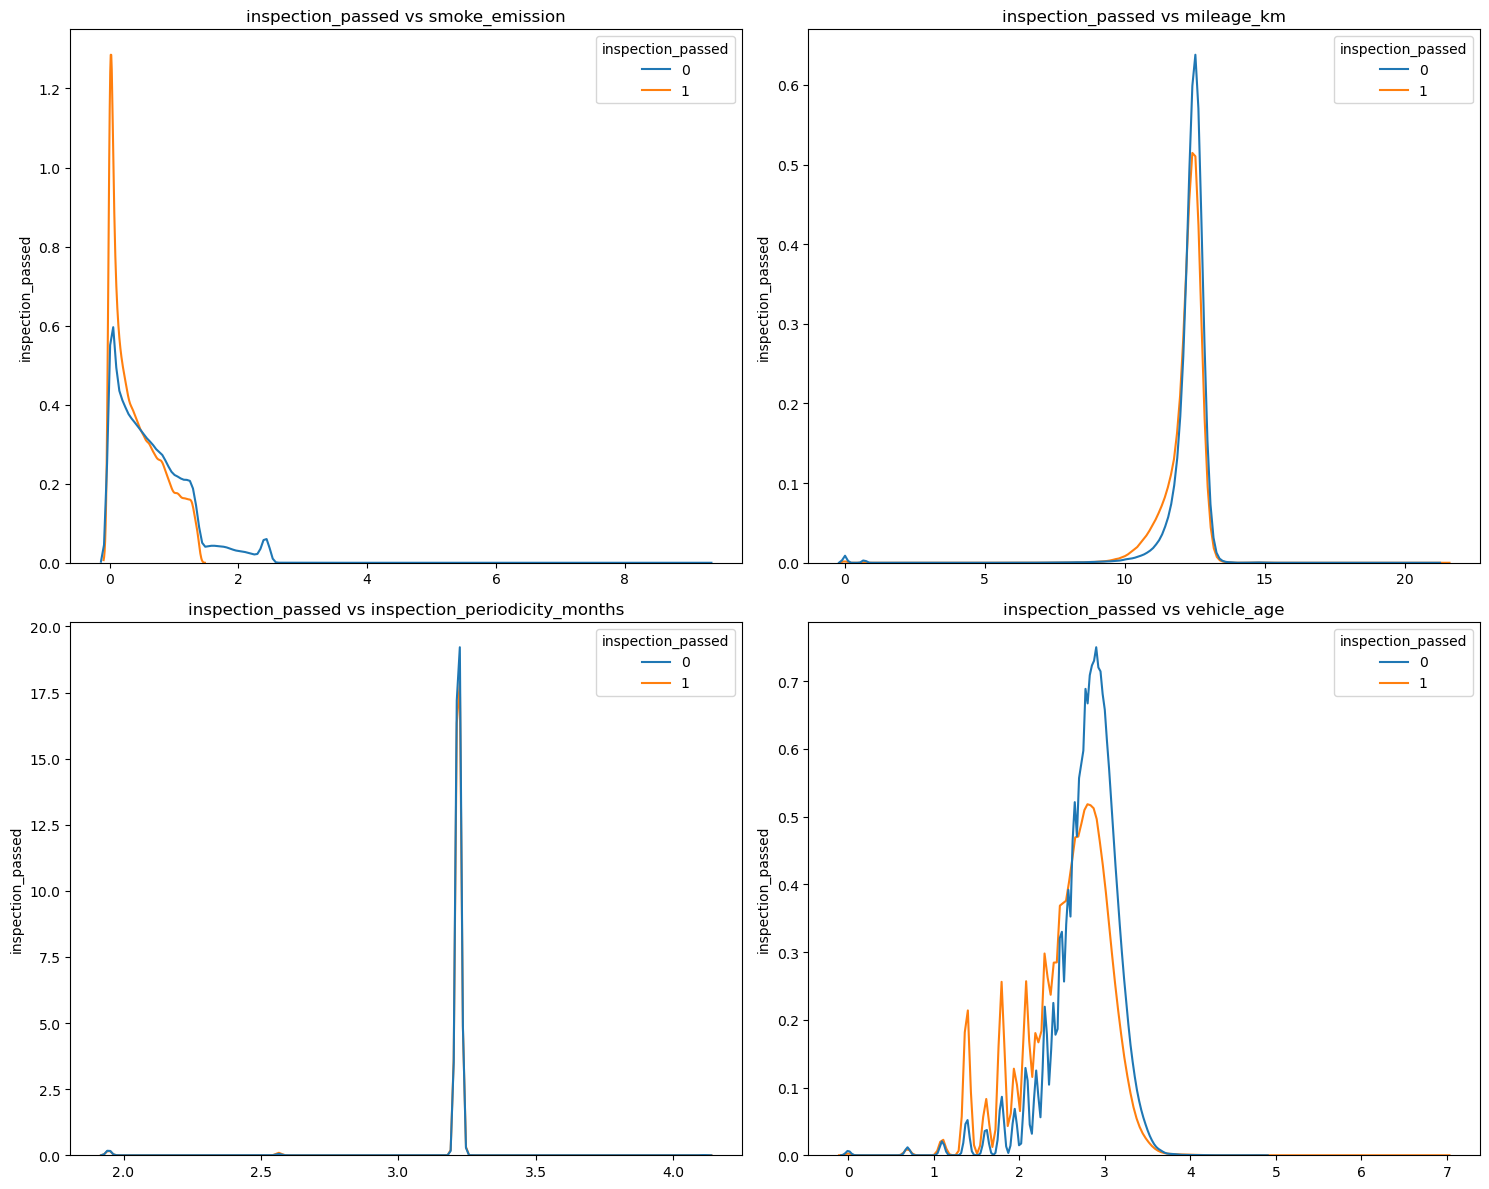

In [ ]:
numerical_predictors = ['smoke_emission', 'mileage_km', 'inspection_periodicity_months', 'vehicle_age']

df_try = pd.DataFrame()
df_try[target] = df[target]
for predictor in numerical_predictors:
    df_try[predictor] = np.log1p(df[predictor])

fig, axs = plt.subplots(2, 2, figsize=(15, 3 * len(numerical_predictors)))
axs = axs.flatten()

for i, predictor in enumerate(numerical_predictors):
    sns.kdeplot(x=predictor, hue=target, data=df_try, ax=axs[i])
    axs[i].set_title(f"{target} vs {predictor}")
    axs[i].set_xlabel(None)
    axs[i].set_ylabel(target)

plt.tight_layout()
plt.show()

Based on the EDA I will choose make, model, body_type, fuel_type (beacuse all these catgorical features have visible diffirence between values), vehicle_age, smoke_emission (because KDE plots have visible difference between passed and not)

In [ ]:
features = [
    'make',
    'model',
    'body_type',
    'fuel_type',
    'vehicle_age',
    'smoke_emission'
]

## Splitting dataset

In [ ]:
from sklearn.model_selection import train_test_split

df_train, df_test = train_test_split(df, test_size=0.2, random_state=10)

## Training Model

Because it took 2 hours to tune hyperparametrs and it wasn't successful, I'll take sample of 10000 rows to tune hyperparametrs

In [ ]:
numerical_features = ['vehicle_age', 'smoke_emission']
categorical_features = ['make', 'model', 'body_type', 'fuel_type']

X_train = df_train[numerical_features + categorical_features]
y_train = df_train[target]

df_hyper = df.sample(n=10000, random_state=42)
X_train_hyper = df_hyper[numerical_features + categorical_features]
y_train_hyper = df_hyper[target]

### Logistic Regression

For numerical features data is skewed => I will use median imputation

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.impute import SimpleImputer

numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('poly', PolynomialFeatures(degree=2)),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='first', max_categories=10, handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, numerical_features),
    ('cat', categorical_pipeline, categorical_features)
])

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

logreg_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('logreg', LogisticRegression(penalty='l1', max_iter=5000, solver='liblinear'))
    ]
)

logreg_param_grid = {
    'logreg__C': [10**i for i in range(-6, 5)],
    'logreg__class_weight': ['balanced', None]
}

logreg_grid_search = GridSearchCV(logreg_model, logreg_param_grid, cv=5, scoring='roc_auc', error_score='raise')
logreg_grid_search.fit(X_train_hyper, y_train_hyper)

print(logreg_grid_search.best_params_)

C:\Users\User\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:242: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:242: UserWarning: Found unknown categories in columns [0, 1, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:242: UserWarning: Found unknown categories in columns [0, 1, 2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:242: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:242: User

{'logreg__C': 0.1, 'logreg__class_weight': None}


Training LogReg model on the whole training set

In [ ]:
logreg_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('logreg', LogisticRegression(penalty='l1', max_iter=5000, solver='liblinear', C=0.1, class_weight=None))
    ]
)

logreg_model.fit(X_train, y_train)

C:\Users\User\anaconda3\Lib\site-packages\sklearn\svm\_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('poly',
                                                                   PolynomialFeatures()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['vehicle_age',
                                                   'smoke_emission']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(drop='first',
                                                                                 handle_unknown='ignore',
                                                                                 max_categories=10))]),
                                                  ['make', 'model', 'body_type',
                                                   'fuel_type'])])),
                ('logreg',
                 LogisticRegression(C=0.1, max_iter=5000, penalty='l1',
                                    solver='liblinear'))])

### Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    ('preprocessing', preprocessor),
    ('rf', RandomForestClassifier(random_state=42))
])

rf_param_grid = {
    'rf__max_depth': range(10, 21),
    'rf__class_weight': ['balanced', None],
    'rf__min_samples_split': range(2, 10),
}

rf_grid_search = GridSearchCV(rf_model, rf_param_grid, cv=5, scoring='roc_auc', n_jobs=-1)
rf_grid_search.fit(X_train_hyper, y_train_hyper)

print(rf_grid_search.best_params_)

{'rf__class_weight': None, 'rf__max_depth': 10, 'rf__min_samples_split': 8}


Training RF model on the whole training set

In [ ]:
rf_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('rf', RandomForestClassifier(class_weight=None, max_depth=10, min_samples_split=8, random_state=42))
    ]
)

rf_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('poly',
                                                                   PolynomialFeatures()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['vehicle_age',
                                                   'smoke_emission']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(drop='first',
                                                                                 handle_unknown='ignore',
                                                                                 max_categories=10))]),
                                                  ['make', 'model', 'body_type',
                                                   'fuel_type'])])),
                ('rf',
                 RandomForestClassifier(max_depth=10, min_samples_split=8,
                                        random_state=42))])

## Choosing Best Model

In [ ]:
from sklearn.model_selection import cross_val_score

logreg_score = np.mean(
    cross_val_score(logreg_model, X_train, y_train, cv=5, scoring='roc_auc')
)

rf_score = np.mean(
    cross_val_score(rf_model, X_train, y_train, cv=5, scoring='roc_auc')
)

if logreg_score > rf_score:
    print('Logistic Regression is the best model')
    best_model = logreg_model
else:
    print('Random Forest is the best model')
    best_model = rf_model

C:\Users\User\anaconda3\Lib\site-packages\sklearn\svm\_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:242: UserWarning: Found unknown categories in columns [0, 1, 2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\svm\_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:242: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\svm\_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
C:\Users\User\anaconda3\Lib\si

Random Forest is the best model


In [ ]:
print(logreg_score)
print(rf_score)

0.6538768743427783
0.6785566357387071


## Reporting Best Model

predict() has a default threshhold of 0.5, confusion matrix is a metric of my choice

C:\Users\User\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:242: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


precision: (0.6424647323523728,), recall: (0.5010280202805257,), f1: (0.5629993407643504,)


C:\Users\User\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:242: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


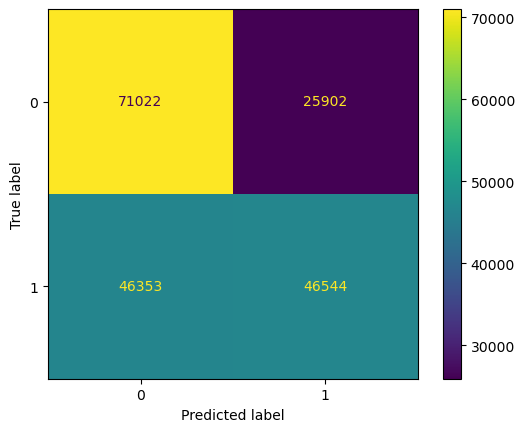

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, precision_score, recall_score, f1_score

y_test = df_test[target]
X_test = df_test.drop(columns=[target])
y_pred = best_model.predict(X_test)

precision = precision_score(y_test, y_pred),
recall = recall_score(y_test, y_pred),
f1 = f1_score(y_test, y_pred),

print(f'precision: {precision}, recall: {recall}, f1: {f1}')

ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test)

Because I am analyzing vehicle inspection, we should care more about false positives, which are the lowest number. Even though, we have to evaluate the prediction based on key metrics. Of all metrics, again due to specifics of dataset (we care about lemon-cars not passing the inspection), we care more about precision. It is equal to 64,2% of predicted inspection passings were actually correct, which is pretty low. Let's try to look at others threshholds

C:\Users\User\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:242: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:242: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:242: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:242: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:242: UserWarnin

<Axes: xlabel='threshold', ylabel='count_positive'>

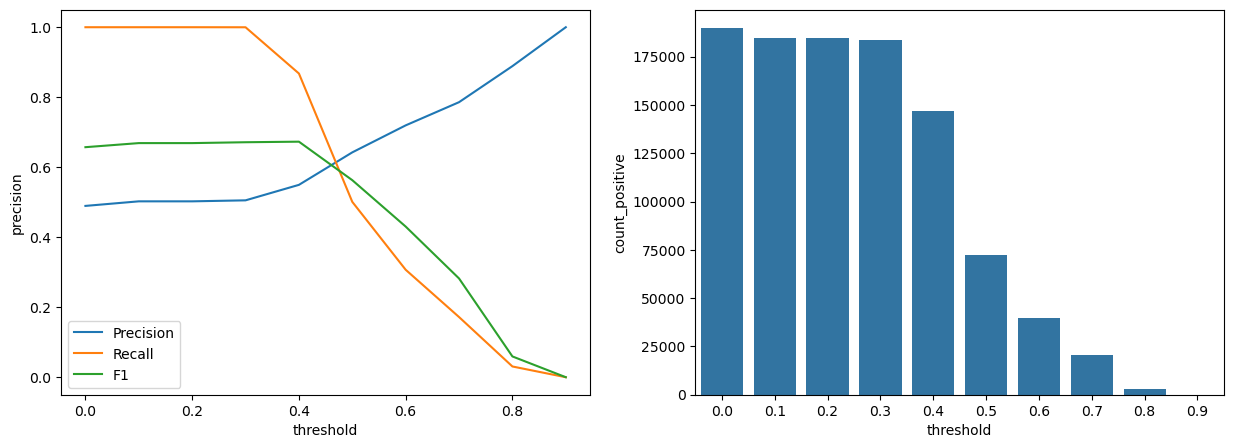

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

fig, axs = plt.subplots(1, 2, figsize=(15, 5))

X_test = df_test.drop(columns=[target])
y_test = df_test[target]

thresholds = np.arange(0, 1, 0.1).round(1)
metrics = []

for threshold in thresholds:
    y_pred = (best_model.predict_proba(X_test)[:, 1] > threshold).astype(int)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    metrics.append(
        {
            'threshold': threshold,
            'precision': precision,
            'recall': recall,
            'count_positive': np.sum(y_pred),
            'f1': f1,
        }
    )

metrics = pd.DataFrame(metrics)
metrics

sns.lineplot(data=metrics, x='threshold', y='precision', label='Precision', ax=axs[0])
sns.lineplot(data=metrics, x='threshold', y='recall', label='Recall', ax=axs[0])
sns.lineplot(data=metrics, x='threshold', y='f1', label='F1', ax=axs[0])
sns.barplot(data=metrics, x='threshold', y='count_positive', ax=axs[1])

F1 score, which is balancing precision and recall starts to peak around 0.3, which means that this is an optimal threshold to balance true and false posisives. But, as mentioned above, we care more about lowest number of false positives. Precision is highest at threshold = 0.4, which would be most optimal threshold for this model. Also from the RHS we can see, that the higher threshold the less cars are classified as passing, after threshold of 0.4 this number is falling dramaticaly, therefore, again, it is better to stick to the threshold of 0.4

## Prediction for a single vehicle of my choice

In [ ]:
time_machine = {
    'make': 'SUZUKI',
    'model': 'BALENO',
    'body_type': 'AC',
    'fuel_type': 'benzinas',
    'inspection_station_municipality': 'Vilniaus m. sav.',
    'inspection_conclusion_en': 'No deficiencies',
    'smoke_emission': 0.1,
    'mileage_km': 100000,
    'inspection_periodicity_months': 12,
    'vehicle_age': 18,
    'end_of_year_inspection': 1
}

time_machine_df = pd.DataFrame([time_machine])

probability = best_model.predict_proba(time_machine_df)[0][1]
prediction = best_model.predict(time_machine_df)[0]

print(f'Probability of passing inspection: {probability:.2f}')
print('Prediction: Time machine is ', 'passing' if prediction == 1 else 'not passing')

Probability of passing inspection: 0.47
Prediction: Time machine is  not passing


Time machine is unfortunately not into operation :(